# Pair Plot (Scatter-plot Matrix)

**Family:** Correlation &nbsp;|&nbsp; **Library:** matplotlib / seaborn

> *Correlation:* Show the relationship between two or more variables.

## Design purpose

A grid of scatter plots for every pair of variables, with each variable's distribution on the diagonal. It is a standard first look at a multivariate dataset.

## When to use

- Explore relationships among 3–6 numeric variables at once
- Check how well groups separate across features (classification problems)
- Find non-linear relationships that a correlation matrix would miss

## Avoid when

- There are more than ~6 variables (the panels get tiny)
- The audience is non-technical (too dense for presentation)

## Alternatives

- Correlation heatmap
- Parallel coordinates

## Example

Four flower measurements for three species (synthetic, iris-like).

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
pio.templates["vizlib"] = go.layout.Template(layout=dict(
    colorway=PALETTE, font=dict(family="Helvetica, Arial, sans-serif", size=13, color="#0b0b0b"),
    paper_bgcolor="#fcfcfb", plot_bgcolor="#fcfcfb", title=dict(x=0.02, xanchor="left"),
    xaxis=dict(gridcolor="#e6e5e1", linecolor="#c9c8c3", zeroline=False),
    yaxis=dict(gridcolor="#e6e5e1", linecolor="#c9c8c3", zeroline=False),
))
pio.templates.default = "plotly_white+vizlib"
pio.renderers.default = "plotly_mimetype+notebook_connected"

### Data

In [2]:
rng = np.random.default_rng(21)
means = {"setosa": [5.0, 3.4, 1.5, 0.25], "versicolor": [5.9, 2.8, 4.3, 1.3],
         "virginica": [6.6, 3.0, 5.6, 2.0]}
sds = [0.35, 0.33, 0.3, 0.15]
rows = []
for sp, mu in means.items():
    x = rng.normal(mu, sds, (50, 4))
    rows.append(pd.DataFrame(x, columns=["sepal_length", "sepal_width",
                                         "petal_length", "petal_width"]).assign(species=sp))
df = pd.concat(rows, ignore_index=True)
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.125571,3.898524,0.964101,0.502992,setosa
1,4.983439,3.136007,1.259113,0.087578,setosa
2,4.921724,3.675182,1.675219,0.345743,setosa
3,4.406817,2.881583,1.966141,0.395333,setosa
4,5.764125,3.799239,1.192683,0.442791,setosa


### Plot

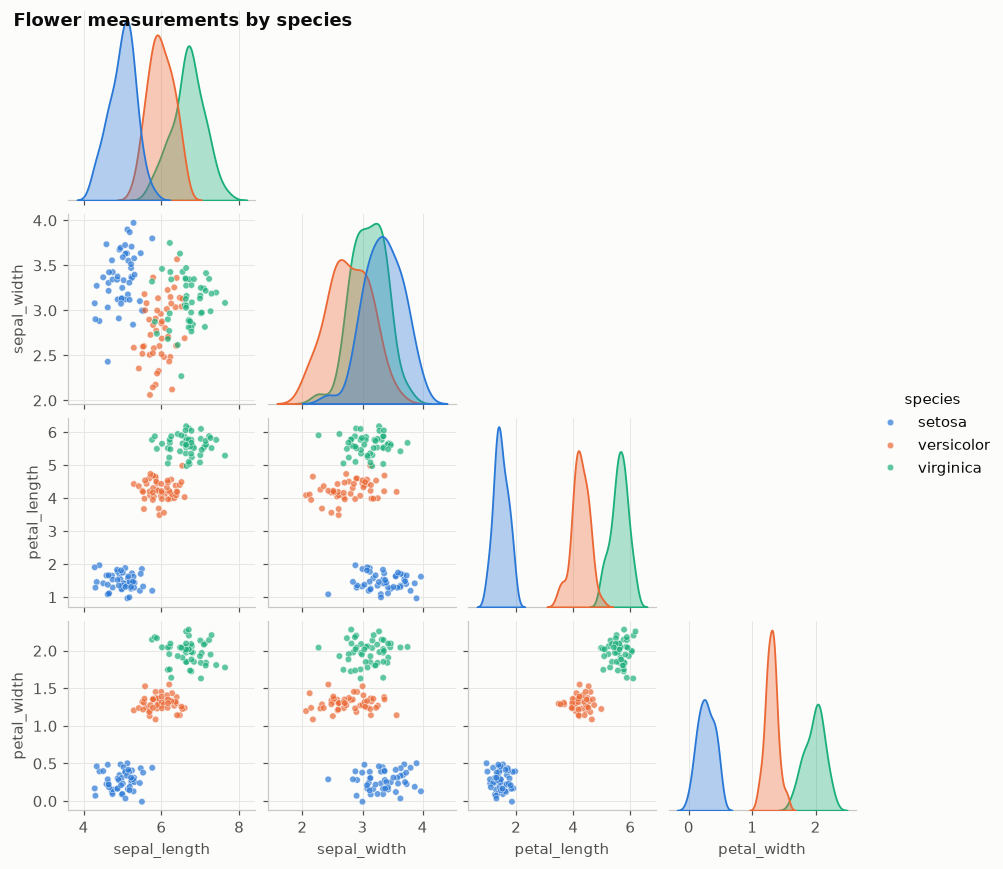

In [3]:
import seaborn as sns
g = sns.pairplot(df, hue="species", palette=PALETTE[:3], height=2, corner=True,
                 plot_kws=dict(s=18, alpha=0.7, edgecolor="#fcfcfb", linewidth=0.4),
                 diag_kws=dict(fill=True, alpha=0.35, linewidth=1.2))
g.figure.suptitle("Flower measurements by species", x=0.02, ha="left", weight="bold")
fig = g.figure
plt.show()

## How to read it

Each off-diagonal panel is a scatter plot of two measurements and the diagonal shows each measurement's distribution. Petal length and width separate the three species almost perfectly.

## The same chart in other libraries

Each version uses the example data above. Pick the library that fits your stack: matplotlib/seaborn for static and print figures, plotly for interactive HTML, Altair for concise declarative specs.

### plotly

In [4]:
import plotly.express as px
fig = px.scatter_matrix(df, dimensions=["sepal_length", "sepal_width", "petal_length", "petal_width"],
                        color="species", color_discrete_sequence=PALETTE, opacity=0.7,
                        title="Flower measurements by species")
fig.update_traces(diagonal_visible=False, showupperhalf=False, marker=dict(size=5))
fig.update_layout(height=650)
fig.show()

## Try it with real data

**Source:** plotly.express.data.iris() — Fisher's (1936) iris measurements, bundled with plotly

The dataset ships with an installed package, so this runs offline. It defines the same variables as the example data, so the plot code is unchanged.

In [5]:
import plotly.express as px
df = px.data.iris()[["sepal_length", "sepal_width", "petal_length", "petal_width", "species"]]
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


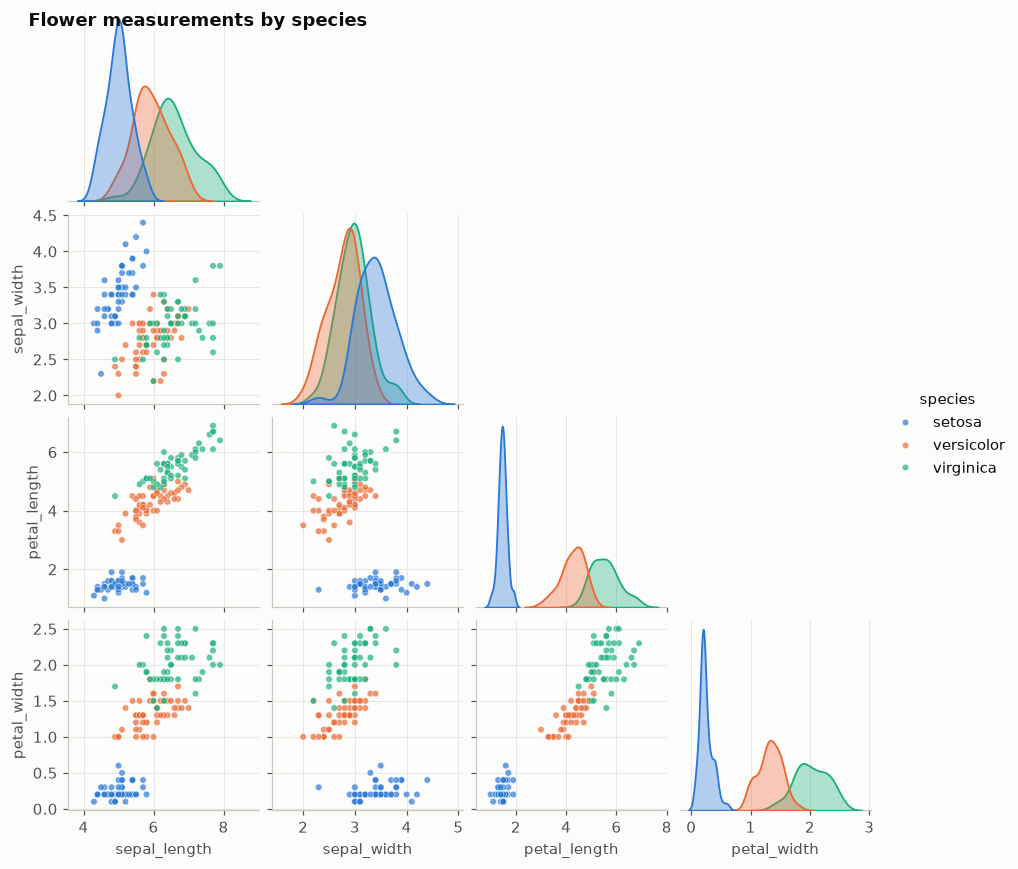

In [6]:
import seaborn as sns
g = sns.pairplot(df, hue="species", palette=PALETTE[:3], height=2, corner=True,
                 plot_kws=dict(s=18, alpha=0.7, edgecolor="#fcfcfb", linewidth=0.4),
                 diag_kws=dict(fill=True, alpha=0.35, linewidth=1.2))
g.figure.suptitle("Flower measurements by species", x=0.02, ha="left", weight="bold")
fig = g.figure
plt.show()

---
Standalone script: [`pair_plot.py`](pair_plot.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)